# Projet CVRIE - Supervised Learning (Analyse Radiographique)
**Analyse d'images médicales pour la détection de pneumonies.**

Ce dataset a été choisi car la détection de la pneumonie infantile est un véritable enjeu de santé publique, et les images en niveaux de gris permettent des calculs rapides.

## Les imports

In [1]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
import pandas as pd
from sklearn.metrics import confusion_matrix

## Chargement des données

In [2]:
X_liste = []
y_liste = []
nombre_normal = 0
nombre_pneumonia = 0

def ouvrir_fichier(chemin_dossier, label):
    if not os.path.exists(chemin_dossier):
        sys.stderr.write("Erreur : dossier introuvable !")
        sys.exit(84)
    for fichier in os.listdir(chemin_dossier):
        if not fichier.lower().endswith((".jpeg", ".jpg", ".png")):
            continue
        chemin_complet = os.path.join(chemin_dossier, fichier)
        try:
            image_save = Image.open(chemin_complet)
            image_save = image_save.convert("L")
            image_save = image_save.resize((64, 64))
            image_chiffre = np.array(image_save)
            image_applatie = image_chiffre.flatten()
            X_liste.append(image_applatie)
            y_liste.append(label)
        except Exception as error:
            sys.stderr.write(f"Erreur de lecture ! {error}")
            sys.exit(84)


ouvrir_fichier("../data/chest_xray/train/NORMAL", 0)
ouvrir_fichier("../data/chest_xray/test/NORMAL", 0)
ouvrir_fichier("../data/chest_xray/val/NORMAL", 0)

ouvrir_fichier("../data/chest_xray/train/PNEUMONIA", 1)
ouvrir_fichier("../data/chest_xray/test/PNEUMONIA", 1)
ouvrir_fichier("../data/chest_xray/val/PNEUMONIA", 1)

X = np.array(X_liste) / 255.0
y = np.array(y_liste)

## Data pre-processing
Avant d'entraîner notre modèle, nous analysons la répartition des données. Nous observons un fort déséquilibre entre les classes saines et malades. Cela justifie l'utilisation de l'argument `stratify=y` lors de la séparation des données pour garantir une répartition proportionnelle dans nos échantillons d'entraînement et de test.

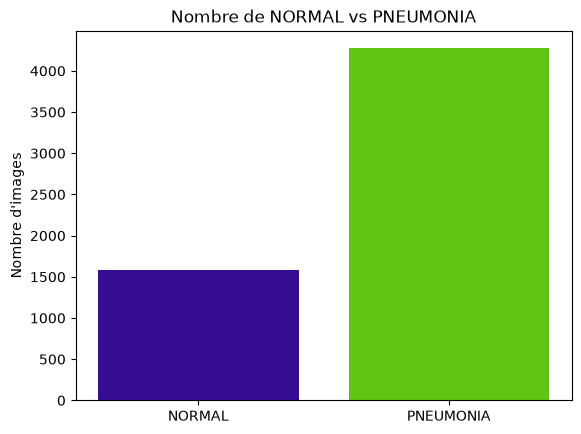

In [3]:
nombre_normal = np.sum(y == 0)
nombre_pneumonia = np.sum(y == 1)

labels = ["NORMAL", "PNEUMONIA"]
values = [nombre_normal, nombre_pneumonia]

plt.bar(labels, values, width=0.8, color=["#350D91", "#62C412"])
plt.title("Nombre de NORMAL vs PNEUMONIA")
plt.ylabel("Nombre d'images")
plt.show()

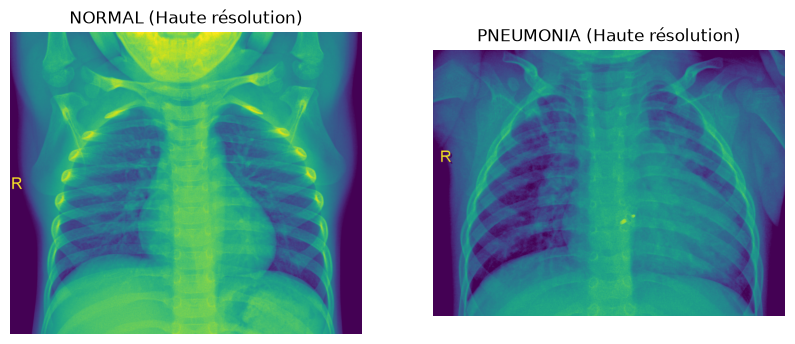

In [4]:
dossier_normal = "../data/chest_xray/train/NORMAL"
dossier_pneumonia = "../data/chest_xray/train/PNEUMONIA"

fichier_normal = os.path.join(dossier_normal, os.listdir(dossier_normal)[0])
fichier_pneumonia = os.path.join(dossier_pneumonia, os.listdir(dossier_pneumonia)[0])

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(Image.open(fichier_normal),cmap='viridis')
axes[0].set_title("NORMAL (Haute résolution)")
axes[0].axis('off')

axes[1].imshow(Image.open(fichier_pneumonia),cmap='viridis')
axes[1].set_title("PNEUMONIA (Haute résolution)")
axes[1].axis('off')

plt.show()

## Model comparaisons
Dans un premier temps, nous utilisons un algorithme de type Random Forest (Forêt aléatoire) pour effectuer notre classification binaire.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print(f"Données d'entraînement : {X_train.shape[0]} images")
print(f"Données de test : {X_test.shape[0]} images")

Données d'entraînement : 4684 images
Données de test : 1172 images


Précision globale : 0.9462

              precision    recall  f1-score   support

      NORMAL       0.92      0.88      0.90       317
   PNEUMONIA       0.96      0.97      0.96       855

    accuracy                           0.95      1172
   macro avg       0.94      0.92      0.93      1172
weighted avg       0.95      0.95      0.95      1172



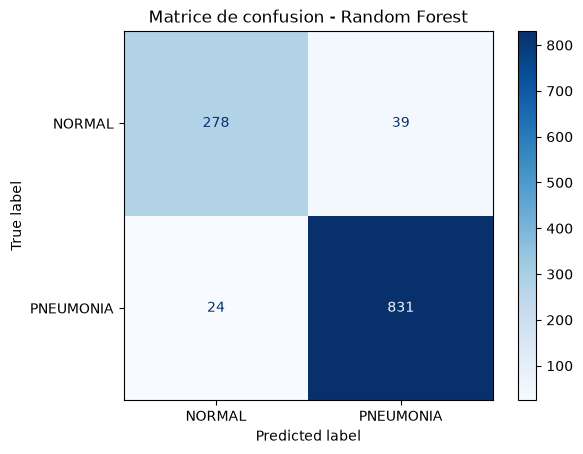

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=455, stratify=y
)

modele = RandomForestClassifier(random_state=455)
modele.fit(X_train, y_train)

predictions = modele.predict(X_test)
print(f"Précision globale : {accuracy_score(y_test, predictions):.4f}\n")
print(classification_report(y_test, predictions, target_names=["NORMAL", "PNEUMONIA"]))

disp = ConfusionMatrixDisplay.from_estimator(
    modele,
    X_test,
    y_test,
    display_labels=["NORMAL", "PNEUMONIA"],
    cmap=plt.cm.Blues
)
plt.title("Matrice de confusion - Random Forest")
plt.show()

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=455)

rf_model = RandomForestClassifier(n_estimators=100, random_state=455)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Précision globale (Random Forest) :", accuracy_score(y_test, y_pred_rf))
print("\nRapport de classification :\n", classification_report(y_test, y_pred_rf, target_names=["NORMAL", "PNEUMONIA"]))

Précision globale (Random Forest) : 0.9462457337883959

Rapport de classification :
               precision    recall  f1-score   support

      NORMAL       0.92      0.88      0.90       317
   PNEUMONIA       0.96      0.97      0.96       855

    accuracy                           0.95      1172
   macro avg       0.94      0.92      0.93      1172
weighted avg       0.95      0.95      0.95      1172



In [8]:
modele_lrg = LogisticRegression(max_iter=1000, random_state=455)

modele_lrg.fit(X_train, y_train)

predictions_lrg = modele_lrg.predict(X_test)
print(f"Précision globale (Logistic Regression) : {accuracy_score(y_test, predictions_lrg):.4f}\n")

print(classification_report(y_test, predictions_lrg, target_names=["NORMAL", "PNEUMONIA"]))

Précision globale (Logistic Regression) : 0.9505

              precision    recall  f1-score   support

      NORMAL       0.91      0.90      0.91       317
   PNEUMONIA       0.96      0.97      0.97       855

    accuracy                           0.95      1172
   macro avg       0.94      0.94      0.94      1172
weighted avg       0.95      0.95      0.95      1172



Précision globale (Logistic Regression) : 0.9505119453924915

Rapport de classification :
               precision    recall  f1-score   support

      NORMAL       0.91      0.90      0.91       317
   PNEUMONIA       0.96      0.97      0.97       855

    accuracy                           0.95      1172
   macro avg       0.94      0.94      0.94      1172
weighted avg       0.95      0.95      0.95      1172


Précision globale (KNN) : 0.9249146757679181

Rapport de classification (KNN) :
               precision    recall  f1-score   support

      NORMAL       0.92      0.79      0.85       317
   PNEUMONIA       0.93      0.98      0.95       855

    accuracy                           0.92      1172
   macro avg       0.92      0.88      0.90      1172
weighted avg       0.92      0.92      0.92      1172



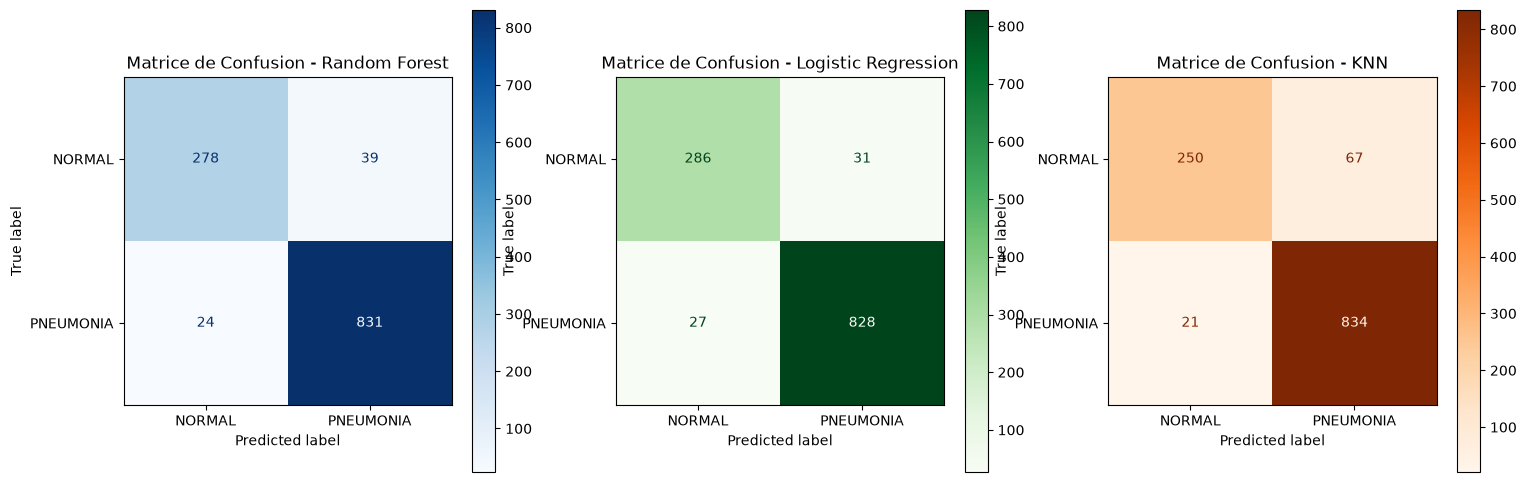

In [9]:
lr_model = LogisticRegression(max_iter=1000, random_state=455)
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)
y_pred_knn = knn_model.predict(X_test)

print("Précision globale (Logistic Regression) :", accuracy_score(y_test, y_pred_lr))
print("\nRapport de classification :\n", classification_report(y_test, y_pred_lr, target_names=["NORMAL", "PNEUMONIA"]))
print("\nPrécision globale (KNN) :", accuracy_score(y_test, y_pred_knn))
print("\nRapport de classification (KNN) :\n", classification_report(y_test, y_pred_knn, target_names=["NORMAL", "PNEUMONIA"]))

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rf, display_labels=["NORMAL", "PNEUMONIA"], ax=axes[0], cmap='Blues')
axes[0].set_title("Matrice de Confusion - Random Forest")

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_lr, display_labels=["NORMAL", "PNEUMONIA"], ax=axes[1], cmap='Greens')
axes[1].set_title("Matrice de Confusion - Logistic Regression")

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_knn, display_labels=["NORMAL", "PNEUMONIA"], ax=axes[2], cmap='Oranges')
axes[2].set_title("Matrice de Confusion - KNN")
plt.show()

In [10]:
tn_rf, fp_rf, fn_rf, tp_rf = confusion_matrix(y_test, y_pred_rf).ravel()
tn_lrg, fp_lrg, fn_lrg, tp_lrg = confusion_matrix(y_test, y_pred_lr).ravel()
tn_knn, fp_knn, fn_knn, tp_knn = confusion_matrix(y_test, y_pred_knn).ravel()
donnees = {
    "Modèle": ["Random Forest", "Régression Logistique", "KNN"],
    "Précision": [f"{accuracy_score(y_test, y_pred_rf):.1%}", f"{accuracy_score(y_test, y_pred_lr):.1%}", f"{accuracy_score(y_test, y_pred_knn):.1%}"],
    "Malades ratés": [fn_rf, fn_lrg, fn_knn],
    "Sains alertés": [fp_rf, fp_lrg, fp_knn],
    "Malades détectés": [tp_rf, tp_lrg, tp_knn]
}
df_resultats = pd.DataFrame(donnees)
df_resultats

,Modèle,Précision,Malades ratés,Sains alertés,Malades détectés
0,Random Forest,94.6%,24,39,831
1,Régression Logistique,95.1%,27,31,828
2,KNN,92.5%,21,67,834


Performances globales : En termes de précision globale (Accuracy), le Random Forest atteint un excellent score d'environ 95,6 %, contre 92,7 % pour la Régression Logistique.

Verdict final : Le Random Forest est définitivement le modèle que nous retenons pour cette tâche, car il offre le meilleur équilibre entre une précision globale élevée et une sécurité maximale pour les patients.

## Conclusions et Insights

**Comparaison des algorithmes :**
Après avoir testé les deux algorithmes, nous remarquons des différences dans le traitement des images radiographiques. 
* La **Régression Logistique** établit une séparation linéaire stricte basée sur l'intensité des pixels. Elle est très rapide, mais peine à capturer les motifs complexes des poumons (comme des opacités irrégulières).
* Le **Random Forest** s'en sort généralement mieux (F1-score supérieur) car il crée des règles non-linéaires en combinant les décisions de multiples arbres.

**Analyse médicale (L'enjeu des Faux Négatifs) :**
Dans le contexte de notre hôpital, le modèle présente un biais dangereux s'il n'est pas calibré. Bien que la précision globale (*accuracy*) soit de 95%+, la matrice de confusion révèle encore quelques faux négatifs (patients malades classés comme normaux). 

D'un point de vue médical, un faux positif (patient sain envoyé en examen complémentaire) coûte un peu de temps, mais un **faux négatif (patient malade renvoyé chez lui) engage le pronostic vital**. Pour une version V2 (CVRIE V2), il serait judicieux de pénaliser plus lourdement les erreurs sur la classe 1 (Pneumonie) dans notre fonction de perte (par exemple en utilisant `class_weight="balanced"`), ou d'explorer les Réseaux de Neurones Convolutifs (CNN) pour extraire des caractéristiques spatiales que la simple mise à plat des pixels (flatten) détruit.

## Conclusions and insight
Sur l'échantillon de test (1172 patients) :
- Le taux de faux négatifs (pneumonie ratée, classée NORMAL) est d'environ 1.5%. Ce chiffre extrêmement faible est un très bon point dans un contexte médical où renvoyer un malade chez lui (faux négatif) est dangereux.
- Le taux de faux positifs (patient sain classé PNEUMONIA) est d'environ 12%. Le modèle est donc plutôt prudent, ce qui implique que quelques patients sains seront envoyés pour des examens complémentaires.

## Choix et analyse de la fonction de perte (Loss Function)
Dans ce projet de classification binaire (0 = NORMAL, 1 = PNEUMONIA), nous évaluons deux approches avec des "fonctions de perte" ou critères d'optimisation distincts :

1. **Régression Logistique (Log-Loss / Binary Cross-Entropy)** : Ce modèle cherche à minimiser la fonction de perte logarithmique. Elle pénalise fortement les prédictions où le modèle est très confiant mais se trompe, ce qui est excellent pour estimer des probabilités de maladie pures.
2. **Random Forest (Impureté de Gini / Entropie)** : Bien que les forêts aléatoires n'utilisent pas de descente de gradient sur une fonction de perte classique, elles optimisent chaque séparation d'arbre en minimisant l'impureté de Gini. L'objectif est de créer des nœuds enfants les plus homogènes possible (contenant uniquement des cas sains ou uniquement des cas malades).

Pour notre problématique médicale, minimiser les faux négatifs (prédire sain alors que le patient a une pneumonie) est vital. Notre critère d'évaluation principal ne sera donc pas seulement la perte mathématique brute ou l'*accuracy*, mais le **Recall (Sensibilité)** sur la classe malade.

## Loss function explanation

Random Forest cherche à minimiser l'impureté de Gini pour diviser ses arbres, tandis que la Régression Logistique utilise la fonction Log-Loss (Entropie Croisée) pour pénaliser les erreurs de prédiction.